# Módulo 18 — Hull-White II: a árvore trinomial

**Curso:** Derivativos com Python. Módulo complementar, construído sobre Clewlow e Strickland, *Implementing Derivatives Models*, caps. 8 e 9; Hull e White (1993, 1994a, 1994b); e a planilha HW_arvore_final.

## O que você vai conseguir fazer ao final

1. Explicar o papel dos preços de Arrow-Debreu ("pure securities") na indução para a frente.
2. Deduzir as probabilidades de uma árvore trinomial e o critério de troca de ramificação.
3. Construir a árvore de Hull-White pelos dois métodos clássicos: o de Clewlow-Strickland (§9.3), usado na planilha, e o de dois estágios de Hull-White (1994).
4. Reproduzir a aba "HW yield" da planilha e localizar um erro que nenhuma conferência de soma detecta.
5. Precificar na árvore opções europeias e americanas sobre títulos, títulos com opção de recompra e caps, e medir a convergência contra as fórmulas do Módulo 17.
6. Entender por que ajustar também a estrutura a termo das volatilidades (aba "HW yield and vol") é delicado.
7. Trocar o Hull-White pelo Black-Karasinski na mesma árvore e ver o que muda.

## Onde estamos

O Módulo 17 deu fórmulas fechadas para títulos, opções europeias e caps. Elas não bastam para opções americanas, títulos com opções embutidas (*callable*, *puttable*) e payoffs dependentes do caminho. A árvore trinomial resolve esses casos e serve de laboratório para modelos sem fórmula fechada, como o Black-Karasinski. É o equivalente, para juros, da árvore CRR do Módulo 6.

## 0. Preparação

As funções da curva sintética e as fórmulas fechadas do Módulo 17 são repetidas aqui, para servir de referência.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.stats import norm
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
RAMPA = ["#86b6ef", "#2a78d6", "#104281"]

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


# curva sintética Nelson-Siegel do Módulo 17
def P_merc(T, b0=0.045, b1=-0.010, b2=0.020, tau=1.5):
    T = np.asarray(T, float); e = np.exp(-T / tau)
    return np.exp(-(b0 * T + b1 * tau * (1 - e) + b2 * tau * (1 - (1 + T / tau) * e)))


A_HW, S_HW = 0.10, 0.010


def sigma_P(T, S, a=A_HW, s=S_HW):
    return s / a * (1 - np.exp(-a * (S - T))) * np.sqrt((1 - np.exp(-2 * a * T)) / (2 * a))


def zbc(T, S, K, a=A_HW, s=S_HW):
    """Call europeia sobre zero-cupom (Jamshidian, Módulo 17)."""
    PT, PS = P_merc(T), P_merc(S); sp = sigma_P(T, S, a, s)
    h = np.log(PS / (K * PT)) / sp + sp / 2
    return PS * norm.cdf(h) - K * PT * norm.cdf(h - sp)


def zbp(T, S, K, a=A_HW, s=S_HW):
    PT, PS = P_merc(T), P_merc(S); sp = sigma_P(T, S, a, s)
    h = np.log(PS / (K * PT)) / sp + sp / 2
    return K * PT * norm.cdf(-h + sp) - PS * norm.cdf(-h)


print("Ambiente pronto.")

Ambiente pronto.


---
## 1. Preços de Arrow-Debreu

**Material: Ireland, *Financial Economics*, cap. 10; Clewlow e Strickland, §8.2**

Um título de Arrow-Debreu ("pure security") paga 1 se, e somente se, um estado específico ocorre numa data específica. Numa árvore, o estado é o nó $(i, j)$. Seu preço hoje, $Q_{i,j}$, é tudo de que precisamos para avaliar qualquer fluxo que dependa só do nó: $V_0 = \sum_jQ_{i,j}\,h_{i,j}$.

Duas propriedades fazem dos $Q$ a ferramenta da calibração:

1. **Somam ao zero-cupom.** Um título que paga 1 em todos os estados da data $i$ é o zero-cupom de prazo $i\Delta t$: $\sum_jQ_{i,j} = P(0, i\Delta t)$.
2. **Se propagam para a frente.** Para chegar ao nó $(i + 1, k)$, é preciso estar em algum $(i, j)$, descontar um período e ir de $j$ para $k$ com probabilidade $q(j, k)$:

$$Q_{i+1,k} = \sum_jQ_{i,j}\,q(j, k)\,e^{-r_{i,j}\Delta t}.$$

É a versão discreta da equação de Kolmogorov para a frente. A indução para a frente permite escolher o parâmetro de cada data ($\theta_i$ ou $\alpha_i$) de modo que $\sum_kQ_{i+1,k}$ seja exatamente o preço de mercado, uma data por vez.

---
## 2. A geometria de uma árvore trinomial

**Material: Clewlow e Strickland, §9.2**

### 2.1 Espaçamento

O tempo avança em passos $\Delta t$. A taxa (ou a variável auxiliar $x$) fica numa grade fixa com espaçamento $\Delta x$. A escolha padrão,

$$\Delta x = \sigma\sqrt{3\Delta t},$$

vem da analogia com diferenças finitas explícitas (Hull e White, 1993): ela dá a melhor relação entre estabilidade e precisão, e faz a probabilidade do ramo central valer $2/3$ quando não há drift.

### 2.2 As probabilidades, passo a passo

De um nó, o processo vai para três nós vizinhos, $k + 1$, $k$, $k - 1$. Seja $\eta$ a distância (em unidades de taxa) entre a média condicional e o nó central $k$. Impomos três condições:

$$p_u + p_m + p_d = 1, \qquad (p_u - p_d)\,\Delta x = \eta, \qquad (p_u + p_d)\,\Delta x^2 = \sigma^2\Delta t + \eta^2.$$

A segunda casa a média; a terceira, o segundo momento ($\text{variância} + \text{média}^2$). Resolvendo:

$$p_u = \frac{\sigma^2\Delta t + \eta^2}{2\Delta x^2} + \frac{\eta}{2\Delta x}, \qquad p_m = 1 - \frac{\sigma^2\Delta t + \eta^2}{\Delta x^2}, \qquad p_d = \frac{\sigma^2\Delta t + \eta^2}{2\Delta x^2} - \frac{\eta}{2\Delta x}.$$

São as fórmulas da planilha (células "pu", "pm", "pd").

### 2.3 Quando trocar de ramificação

Com reversão à média, a média condicional de $x$ a partir do nó $j$ é $j\Delta x(1 + M)$, com $M = -a\Delta t$. Na ramificação normal (para $j + 1$, $j$, $j - 1$), $\eta = jM\Delta x$, e com $\Delta x^2 = 3\sigma^2\Delta t$ as probabilidades viram

$$p_u = \tfrac16 + \tfrac12(j^2M^2 + jM), \qquad p_m = \tfrac23 - j^2M^2, \qquad p_d = \tfrac16 + \tfrac12(j^2M^2 - jM).$$

$p_m > 0$ exige $|jM| < 0{,}816$. Longe do centro, a reversão empurra a média para baixo (ou para cima) mais que um $\Delta x$, e $p_d$ (ou $p_u$) ficaria negativa. A solução de Hull e White é trocar a ramificação: no topo, ir para $j$, $j - 1$, $j - 2$; na base, para $j + 2$, $j + 1$, $j$. As probabilidades nesses casos são válidas para $0{,}184 < |jM| < 0{,}816$. Hull e White escolhem trocar no primeiro $j$ com $|jM| > 0{,}184$:

$$j_{max} = \Big\lceil\frac{0{,}184}{a\,\Delta t}\Big\rceil.$$

Isso dá à árvore uma largura máxima: ela para de crescer, o que também a deixa eficiente.

### Laboratório 1 — As probabilidades em toda a grade

In [2]:
def probabilidades(j, M, jmax):
    """Destino do nó central k e probabilidades (p_u, p_m, p_d) da árvore de Hull-White."""
    jm = j * M
    if j == jmax:
        return j - 1, (7 / 6 + (jm**2 + 3 * jm) / 2, -1 / 3 - jm**2 - 2 * jm, 1 / 6 + (jm**2 + jm) / 2)
    if j == -jmax:
        return j + 1, (1 / 6 + (jm**2 - jm) / 2, -1 / 3 - jm**2 + 2 * jm, 7 / 6 + (jm**2 - 3 * jm) / 2)
    return j, (1 / 6 + (jm**2 + jm) / 2, 2 / 3 - jm**2, 1 / 6 + (jm**2 - jm) / 2)


dt1 = 0.25
M1 = -A_HW * dt1
jmax1 = int(np.ceil(0.184 / (A_HW * dt1)))
dx1 = S_HW * np.sqrt(3 * dt1)
linhas = []
for j in range(-jmax1, jmax1 + 1):
    k, (pu, pm, pdn) = probabilidades(j, M1, jmax1)
    media = (pu * (k + 1) + pm * k + pdn * (k - 1)) * dx1
    var = (pu * (k + 1) ** 2 + pm * k**2 + pdn * (k - 1) ** 2) * dx1**2 - media**2
    linhas.append((j, k, pu, pm, pdn, media / dx1, j * (1 + M1), var / (S_HW**2 * dt1)))
tab1 = pd.DataFrame(linhas, columns=["j", "nó central k", "p_u", "p_m", "p_d", "média/Δx", "alvo j(1+M)", "variância/(σ²Δt)"])
print(f"Δt = {dt1}, a = {A_HW}: j_max = {jmax1}")
tabela(tab1)
ok((tab1[["p_u", "p_m", "p_d"]] > 0).all().all(), "todas as probabilidades são positivas, inclusive nas bordas")
ok(np.allclose(tab1["média/Δx"], tab1["alvo j(1+M)"]), "a média condicional é a do processo discretizado em todos os nós")
ok(np.allclose(tab1["variância/(σ²Δt)"], 1), "e a variância também")

Δt = 0.25, a = 0.1: j_max = 8


,j,nó central k,p_u,p_m,p_d,média/Δx,alvo j(1+M),variância/(σ²Δt)
0,-8,-7,"0,087","0,027","0,887","-7,800","-7,800","1,000"
1,-7,-7,"0,269","0,636","0,094","-6,825","-6,825","1,000"
2,-6,-6,"0,253","0,644","0,103","-5,850","-5,850","1,000"
3,-5,-5,"0,237","0,651","0,112","-4,875","-4,875","1,000"
4,-4,-4,"0,222","0,657","0,122","-3,900","-3,900","1,000"
5,-3,-3,"0,207","0,661","0,132","-2,925","-2,925","1,000"
6,-2,-2,"0,193","0,664","0,143","-1,950","-1,950","1,000"
7,-1,-1,"0,179","0,666","0,154","-0,975","-0,975","1,000"
8,0,0,"0,167","0,667","0,167","0,000","0,000","1,000"
9,1,1,"0,154","0,666","0,179","0,975","0,975","1,000"


OK — todas as probabilidades são positivas, inclusive nas bordas
OK — a média condicional é a do processo discretizado em todos os nós
OK — e a variância também


---
## 3. O método de Clewlow e Strickland e a planilha

**Material: Clewlow e Strickland, §9.3; planilha, aba "HW yield"**

### 3.1 A construção

A taxa nos nós é $r_{i,j} = r_{0,0} + j\Delta r$, com $r_{0,0} = R(1)$, o yield do prazo $\Delta t$. O drift no nó é $\mu_{i,j} = (\theta_i - a\,r_{i,j})\,\Delta t$, e as probabilidades são as da Seção 2.2 com $\eta = \mu_{i,j}$ (ramificação normal) ou $\eta = \mu_{i,j} + (j - k)\Delta r$ (ramificação deslocada).

**Como achar $\theta_i$.** Com a árvore construída até a data $i$, escolhe-se $\theta_i$ para acertar o título de prazo $(i + 2)\Delta t$:

$$P(0, (i + 2)\Delta t) = \sum_jQ_{i,j}\,e^{-r_{i,j}\Delta t}\,\mathbb{E}\big[e^{-r_{i+1}\Delta t}\,\big|\,r_{i,j}\big].$$

Aproximando $\mathbb{E}[e^{-r_{i+1}\Delta t}] \approx \exp(-\mathbb{E}[r_{i+1}]\Delta t + \tfrac12\sigma^2\Delta t^3)$, com $\mathbb{E}[r_{i+1}] = r_{i,j} + (\theta_i - a\,r_{i,j})\Delta t$, e isolando $\theta_i$:

$$\theta_i = \frac{(i + 2)R(i + 2)}{\Delta t} + \frac{\sigma^2\Delta t}{2} + \frac{1}{\Delta t^2}\ln\sum_jQ_{i,j}\,e^{-2r_{i,j}\Delta t + a\,r_{i,j}\Delta t^2}.$$

É a fórmula das células B39 a D39 da planilha.

### Laboratório 2 — Reproduzir a aba "HW yield"

Entradas da planilha: data 03/01/2024; yields de 1 a 4 meses: 5,27%, 5,28%, 5,24% e 5,21%; $\Delta t = 30/360$; $\sigma = 0{,}024638$ e $a = 0{,}0527$ (as mesmas células do Módulo 17).

In [3]:
R_pl = np.array([0.0527, 0.0528, 0.0524, 0.0521])
dt_pl, s_pl, a_pl = 30 / 360, 0.02463782739818595, 0.0527
dr_pl = s_pl * np.sqrt(3 * dt_pl)
P_pl = np.exp(-R_pl * np.arange(1, 5) * dt_pl)


def arvore_cs(R, dt, s, a, n_passos, deslocar_no_menos1=False):
    """Árvore de Clewlow-Strickland §9.3 com ramificação normal, como na planilha.
    deslocar_no_menos1=True reproduz as fórmulas das células D75, D80 e D86 da planilha."""
    dr = s * np.sqrt(3 * dt)
    Q = {0: np.array([1.0])}
    thetas, probs = [], {}
    for i in range(n_passos):
        js = np.arange(-i, i + 1)
        r = R[0] + js * dr
        soma = np.sum(Q[i] * np.exp(-2 * r * dt + a * r * dt**2))
        th = (i + 2) * R[i + 1] / dt + s**2 * dt / 2 + np.log(soma) / dt**2
        thetas.append(th)
        mu = (th - a * r) * dt
        pu = (s**2 * dt + mu**2) / (2 * dr**2) + mu / (2 * dr)
        pm = 1 - (s**2 * dt + mu**2) / dr**2
        pd_ = 1 - pu - pm
        probs[i] = (pu, pm, pd_)
        Qn = np.zeros(2 * i + 3)
        for idx, j in enumerate(js):
            c = j + i + 1                                     # posição de j na data i+1
            if deslocar_no_menos1 and i == 1 and j == -1:
                c += 1                                        # o erro: os ramos do nó (1,-1) sobem um nível
            q = Q[i][idx] * np.exp(-r[idx] * dt)
            Qn[c + 1] += q * pu[idx]; Qn[c] += q * pm[idx]; Qn[c - 1] += q * pd_[idx]
        Q[i + 1] = Qn
    return np.array(thetas), Q, probs


th_ok, Q_ok, pr_ok = arvore_cs(R_pl, dt_pl, s_pl, a_pl, 3)
th_pl, Q_pl, _ = arvore_cs(R_pl, dt_pl, s_pl, a_pl, 3, deslocar_no_menos1=True)

planilha_theta = [0.0052025826057877644, -0.012736624924031048, -0.04884807241485989]
planilha_Q1 = [0.15790312019740224, 0.6634773214221333, 0.1742375209805194]           # j = -1, 0, 1
planilha_Q2 = [0.18333158340384287, 0.5758209294059917, 0.2116414931613954, 0.02044460069953802]  # j = -1..2
tab2 = pd.DataFrame({"i": [0, 1, 2], "θ_i planilha (% a.a.)": 100 * np.array(planilha_theta),
                     "θ_i reproduzido, como na planilha (% a.a.)": 100 * th_pl,
                     "θ_i com a ramificação correta (% a.a.)": 100 * th_ok})
tabela(tab2)
tab2b = pd.DataFrame({"j": [-2, -1, 0, 1, 2], "Q_2,j planilha": [0.0] + planilha_Q2,
                      "Q_2,j correto": Q_ok[2]})
tabela(tab2b)
print("Σ Q_2 planilha:", f"{sum(planilha_Q2):.12f}", "| correto:", f"{Q_ok[2].sum():.12f}", "| P(0, 2Δt):", f"{P_pl[1]:.12f}")
print("Σ Q_3 correto:", f"{Q_ok[3].sum():.12f}", "| P(0, 3Δt):", f"{P_pl[2]:.12f}")

ok(np.allclose(th_pl, planilha_theta, rtol=1e-10), "os três θ_i da planilha são reproduzidos exatamente")
ok(np.allclose(Q_ok[1], planilha_Q1, rtol=1e-12), "os preços de Arrow-Debreu da data 1 conferem")
ok(np.allclose(Q_pl[2][1:], planilha_Q2, rtol=1e-12), "os da data 2 conferem com a versão deslocada")
ok(abs(Q_ok[2].sum() - P_pl[1]) < 1e-14 and abs(sum(planilha_Q2) - P_pl[1]) < 1e-14,
   "as duas versões somam exatamente o zero-cupom de 2 meses: a conferência de soma não vê o erro")
ok(abs(th_pl[2] - th_ok[2]) > 0.04, "mas θ_2 muda mais de 4 pontos percentuais por ano")
ok(abs(Q_ok[3].sum() - P_pl[2]) < 1e-11, "com a ramificação correta, a aproximação de θ_i acerta também o título de 3 meses")

,i,θ_i planilha (% a.a.),"θ_i reproduzido, como na planilha (% a.a.)",θ_i com a ramificação correta (% a.a.)
0,0,"0,520","0,520","0,520"
1,1,"-1,274","-1,274","-1,274"
2,2,"-4,885","-4,885","-0,196"


,j,"Q_2,j planilha","Q_2,j correto"
0,-2,"0,000","0,035"
1,-1,"0,183","0,252"
2,0,"0,576","0,492"
3,1,"0,212","0,193"
4,2,"0,020","0,020"


Σ Q_2 planilha: 0.991238606671 | correto: 0.991238606671 | P(0, 2Δt): 0.991238606671
Σ Q_3 correto: 0.986985431542 | P(0, 3Δt): 0.986985431542
OK — os três θ_i da planilha são reproduzidos exatamente
OK — os preços de Arrow-Debreu da data 1 conferem
OK — os da data 2 conferem com a versão deslocada
OK — as duas versões somam exatamente o zero-cupom de 2 meses: a conferência de soma não vê o erro
OK — mas θ_2 muda mais de 4 pontos percentuais por ano
OK — com a ramificação correta, a aproximação de θ_i acerta também o título de 3 meses


**O que aconteceu.** Nas células D75, D80 e D86, os três ramos que saem do nó $(1, -1)$ são somados aos nós $(2, 1)$, $(2, 0)$ e $(2, -1)$, quando deveriam ir para $(2, 0)$, $(2, -1)$ e $(2, -2)$. A massa total não muda, e por isso $\sum_jQ_{2,j}$ continua igual ao preço do zero-cupom: a conferência que a planilha faz (linha "sum(Q)") passa. Mas a distribuição das taxas fica deslocada para cima, e $\theta_2$, que depende de **onde** a massa está, sai $-4{,}9\%$ em vez de $-0{,}2\%$ ao ano.

Lição de validação: uma conferência que só olha totais não detecta erros de posição. Aqui, o teste que pega o erro é conferir a média e a variância condicionais em cada nó (Laboratório 1) ou reprecificar um instrumento que dependa da distribuição, como uma opção.

---
## 4. O método de dois estágios de Hull e White (1994)

**Material: Clewlow e Strickland, §9.5; Hull e White, 1994a**

O método que se tornou padrão separa a forma da árvore do ajuste à curva.

**Estágio 1 — a árvore de $x$.** $x$ segue o OU sem drift de longo prazo, $dx = -a\,x\,dt + \sigma\,dW$, com $x_0 = 0$. A árvore de $x$ é simétrica, com a geometria e as probabilidades da Seção 2, e não depende da curva.

**Estágio 2 — o deslocamento.** A taxa do período no nó $(m, j)$ é $r_{m,j} = \alpha_m + j\Delta x$. Com os $Q_{m,j}$ conhecidos, $\alpha_m$ sai do zero-cupom de prazo $(m + 1)\Delta t$:

$$P(0, (m + 1)\Delta t) = \sum_jQ_{m,j}\,e^{-(\alpha_m + j\Delta x)\Delta t} \quad\Longrightarrow\quad \alpha_m = \frac{1}{\Delta t}\ln\frac{\sum_jQ_{m,j}\,e^{-j\Delta x\Delta t}}{P(0, (m + 1)\Delta t)}.$$

Sem aproximação: a árvore reproduz a curva **exatamente** em todas as datas da grade. O $\alpha_m$ é a versão discreta do $\varphi(t)$ do Módulo 17.

### Laboratório 3 — A árvore de dois estágios

10 anos, passo mensal: 120 passos, j_max = 23, construída em 0.01 s


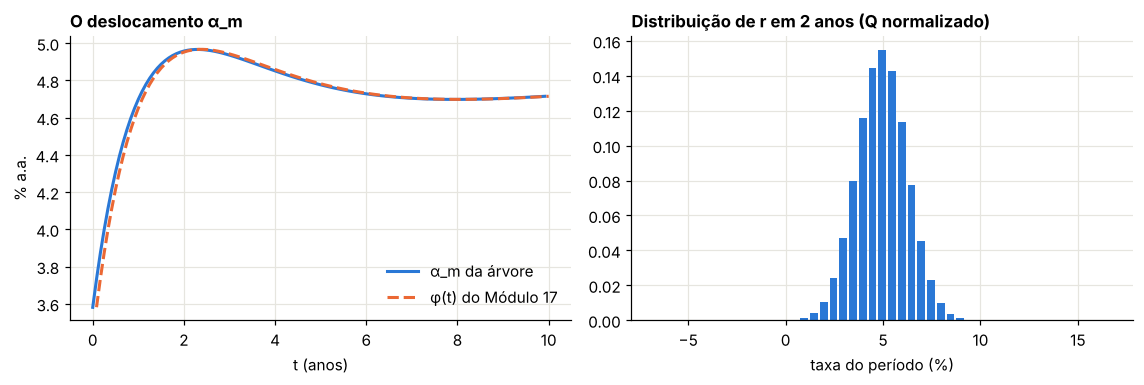

OK — a árvore reprecifica todos os 120 zero-cupons exatamente
OK — α_m acompanha o φ(t) contínuo a menos de 5 pb
OK — a largura máxima é a de Hull-White


In [4]:
class ArvoreTaxaCurta:
    """Árvore trinomial de Hull-White (1994). modelo='HW': r = α_m + x; modelo='BK': ln r = α_m + x."""

    def __init__(self, a, s, dt, N, P, modelo="HW"):
        self.a, self.s, self.dt, self.N, self.modelo = a, s, dt, N, modelo
        self.dx = s * np.sqrt(3 * dt)
        M = -a * dt
        self.jmax = J = int(np.ceil(0.184 / (a * dt)))
        self.js = np.arange(-J, J + 1)
        self.k = np.zeros(2 * J + 1, dtype=int)
        self.p = np.zeros((2 * J + 1, 3))
        for idx, j in enumerate(self.js):
            self.k[idx], self.p[idx] = probabilidades(j, M, J)
        self.alpha = np.zeros(N)
        self.Q = []
        Q = np.zeros(2 * J + 1); Q[J] = 1.0
        for m in range(N):
            nm = min(m, J)
            vivos = slice(J - nm, J + nm + 1)
            x = self.js[vivos] * self.dx
            alvo = P((m + 1) * dt)
            if modelo == "HW":
                self.alpha[m] = np.log(np.sum(Q[vivos] * np.exp(-x * dt)) / alvo) / dt
            else:                                             # BK: Newton-Raphson em α_m
                al = np.log(-np.log(alvo) / ((m + 1) * dt)) if m == 0 else self.alpha[m - 1]
                for _ in range(60):
                    rr = np.exp(al + x)
                    g = np.sum(Q[vivos] * np.exp(-rr * dt)) - alvo
                    al -= g / np.sum(-Q[vivos] * np.exp(-rr * dt) * rr * dt)
                    if abs(g) < 1e-15:
                        break
                self.alpha[m] = al
            self.Q.append(Q.copy())
            d = Q * np.exp(-self.taxa(m) * dt)
            Qn = np.zeros_like(Q)
            for idx in range(J - nm, J + nm + 1):
                c = self.k[idx] + J
                Qn[c + 1] += d[idx] * self.p[idx, 0]; Qn[c] += d[idx] * self.p[idx, 1]; Qn[c - 1] += d[idx] * self.p[idx, 2]
            Q = Qn
        self.Q.append(Q)

    def taxa(self, m):
        x = self.alpha[m] + self.js * self.dx
        return x if self.modelo == "HW" else np.exp(x)

    def voltar(self, V, m):
        """Valor em m (todos os nós) de um vetor de valores V na data m+1."""
        c = self.k + self.jmax
        cont = self.p[:, 0] * V[c + 1] + self.p[:, 1] * V[c] + self.p[:, 2] * V[c - 1]
        return np.exp(-self.taxa(m) * self.dt) * cont

    def zero_cupom(self, m_ini, m_fim):
        V = np.ones(2 * self.jmax + 1)
        for m in range(m_fim - 1, m_ini - 1, -1):
            V = self.voltar(V, m)
        return V


dt3, N3 = 1 / 12, 120
t0 = time.time()
arv = ArvoreTaxaCurta(A_HW, S_HW, dt3, N3, P_merc)
print(f"10 anos, passo mensal: {N3} passos, j_max = {arv.jmax}, construída em {time.time() - t0:.2f} s")
datas = np.arange(1, N3 + 1) * dt3
erro_curva = np.array([abs(arv.Q[m].sum() - P_merc(m * dt3)) for m in range(1, N3 + 1)])
phi = lambda t: -np.log(P_merc(t + 1e-6) / P_merc(t - 1e-6)) / 2e-6 + S_HW**2 / (2 * A_HW**2) * (1 - np.exp(-A_HW * t)) ** 2

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
axs[0].plot(np.arange(N3) * dt3, 100 * arv.alpha, color=AZUL, label="α_m da árvore")
axs[0].plot(datas, 100 * phi(datas - dt3 / 2), "--", color=LARANJA, label="φ(t) do Módulo 17")
axs[0].set_xlabel("t (anos)"); axs[0].set_ylabel("% a.a."); axs[0].set_title("O deslocamento α_m"); axs[0].legend()
mm = 24
axs[1].bar(arv.taxa(mm) * 100, arv.Q[mm] / arv.Q[mm].sum(), width=arv.dx * 80, color=RAMPA[1])
axs[1].set_xlabel("taxa do período (%)"); axs[1].set_title("Distribuição de r em 2 anos (Q normalizado)")
plt.tight_layout(); plt.show()

ok(erro_curva.max() < 1e-14, "a árvore reprecifica todos os 120 zero-cupons exatamente")
ok(np.abs(arv.alpha[1:] - phi(np.arange(1, N3) * dt3 + dt3 / 2)).max() < 5e-4, "α_m acompanha o φ(t) contínuo a menos de 5 pb")
ok(arv.jmax == int(np.ceil(0.184 / (A_HW * dt3))), "a largura máxima é a de Hull-White")

---
## 5. Avaliar na árvore

**Material: Clewlow e Strickland, §9.9; Aula 3 (bond options, callable e puttable bonds)**

Com a árvore pronta, avaliar é indução para trás: o valor num nó é o valor esperado nos três sucessores, descontado pela taxa do nó. Para exercício antecipado, compara-se o valor de continuação com o de exercício em cada data permitida.

### 5.1 Convergência para a fórmula fechada

Call europeia com vencimento em 1 ano sobre o zero-cupom de 5 anos, strike no dinheiro a termo (como no Laboratório 4 do Módulo 17).

,passos por ano,j_max,árvore (pb),Σ Q·payoff (pb),erro (pb),tempo (s)
0,4,8,"94,609","94,609","-4,288","0,001"
1,12,23,"97,816","97,816","-1,081","0,003"
2,24,45,"98,468","98,468","-0,429","0,011"
3,52,96,"98,772","98,772","-0,125","0,050"
4,100,184,"98,874","98,874","-0,023","0,169"
5,200,368,"98,913","98,913","0,017","0,657"


Jamshidian: 98,897 pb
inclinação log-log do erro: -1,579


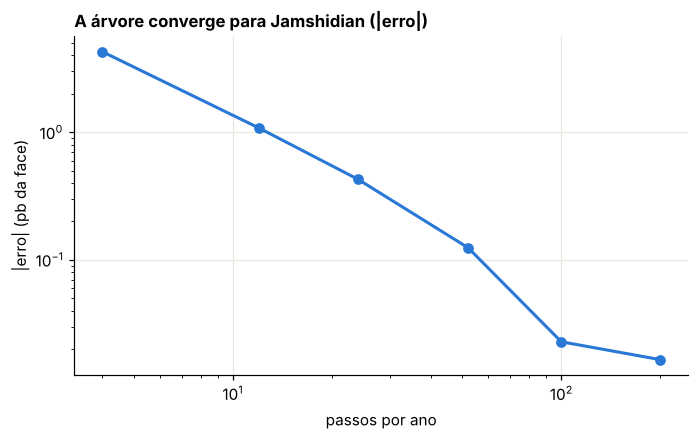

OK — indução para trás e soma dos preços de Arrow-Debreu dão o mesmo valor
OK — com 200 passos por ano, o erro fica abaixo de 0,05 pb
OK — até 100 passos por ano, o erro cai pelo menos na proporção de 1/N
OK — e perto de 200 passos muda de sinal: a convergência não é monótona


In [5]:
T5, S5 = 1.0, 5.0
K5 = P_merc(S5) / P_merc(T5)
ref5 = zbc(T5, S5, K5)
linhas = []
for por_ano in [4, 12, 24, 52, 100, 200]:
    dt = 1 / por_ano
    N = int(round(S5 / dt)); nT = int(round(T5 / dt))
    t0 = time.time()
    arv5 = ArvoreTaxaCurta(A_HW, S_HW, dt, N, P_merc)
    PS = arv5.zero_cupom(nT, N)
    payoff = np.maximum(PS - K5, 0)
    V = payoff.copy()
    for m in range(nT - 1, -1, -1):
        V = arv5.voltar(V, m)
    via_AD = np.sum(arv5.Q[nT] * payoff)
    linhas.append((por_ano, arv5.jmax, 1e4 * V[arv5.jmax], 1e4 * via_AD, 1e4 * (V[arv5.jmax] - ref5), time.time() - t0))
tab5 = pd.DataFrame(linhas, columns=["passos por ano", "j_max", "árvore (pb)", "Σ Q·payoff (pb)", "erro (pb)", "tempo (s)"])
tabela(tab5)
print("Jamshidian:", f3(1e4 * ref5), "pb")
sel = tab5["passos por ano"] <= 100
incl = np.polyfit(np.log(tab5.loc[sel, "passos por ano"]), np.log(np.abs(tab5.loc[sel, "erro (pb)"])), 1)[0]
print("inclinação log-log do erro:", f3(incl))

fig, ax = plt.subplots()
ax.loglog(tab5["passos por ano"], np.abs(tab5["erro (pb)"]), "o-", color=AZUL)
ax.set_xlabel("passos por ano"); ax.set_ylabel("|erro| (pb da face)"); ax.set_title("A árvore converge para Jamshidian (|erro|)")
plt.show()

ok(np.allclose(tab5["árvore (pb)"], tab5["Σ Q·payoff (pb)"], rtol=1e-10), "indução para trás e soma dos preços de Arrow-Debreu dão o mesmo valor")
ok(abs(tab5["erro (pb)"].iloc[-1]) < 0.05, "com 200 passos por ano, o erro fica abaixo de 0,05 pb")
ok(incl < -0.9, "até 100 passos por ano, o erro cai pelo menos na proporção de 1/N")
ok(tab5["erro (pb)"].iloc[-1] * tab5["erro (pb)"].iloc[-2] < 0, "e perto de 200 passos muda de sinal: a convergência não é monótona")

O erro cai depressa (mais rápido que $1/N$ no começo) e troca de sinal perto de 200 passos por ano: como na árvore CRR (Módulo 6), a convergência não é monótona, porque a posição do strike em relação aos nós muda com $N$. Na prática, compara-se o resultado de duas ou três malhas, e não de uma só.

### 5.2 Opções americanas e títulos com opções embutidas

Três produtos sobre a mesma árvore (passo semanal):

* **put americana** sobre o zero-cupom de 5 anos, exercível até 1 ano, com strike igual ao preço à vista do título, $P(0, 5)$ (um strike no dinheiro *a termo* ficaria acima do preço à vista, e o exercício imediato seria ótimo);
* **título com opção de recompra** (*callable*): cupom anual de 5%, vencimento em 5 anos, o emissor pode resgatar ao par em cada data de cupom a partir do ano 2;
* **título com opção de venda** (*puttable*): o mesmo, mas quem pode devolver ao par é o investidor.

Pela Aula 3: a opção de recompra é do emissor, por isso o *callable* vale **menos** que o título simples (o investidor vende a call); o *puttable* vale **mais** (o investidor compra a put).

In [6]:
dt6 = 1 / 52
N6 = int(round(5 / dt6))
arv6 = ArvoreTaxaCurta(A_HW, S_HW, dt6, N6, P_merc)
J6 = arv6.jmax
idx = lambda t: int(round(t / dt6))

# put americana sobre o zero-cupom
nT = idx(1.0)
PS = [None] * (N6 + 1)
V = np.ones(2 * J6 + 1)
for m in range(N6 - 1, -1, -1):
    V = arv6.voltar(V, m)
    PS[m] = V
K_am = P_merc(5.0)                       # strike igual ao preço à vista do título
put_eur = np.maximum(K_am - PS[nT], 0); put_am = put_eur.copy()
for m in range(nT - 1, -1, -1):
    put_eur = arv6.voltar(put_eur, m)
    put_am = np.maximum(arv6.voltar(put_am, m), K_am - PS[m])
premio_am = put_am[J6] - put_eur[J6]
print("put europeia:", f3(1e4 * put_eur[J6]), "pb | americana:", f3(1e4 * put_am[J6]), "pb | Jamshidian:", f3(1e4 * zbp(1.0, 5.0, K_am)), "pb")


# títulos com cupom
def titulo(opcao=None, cupom=0.05, datas_opcao=(2, 3, 4)):
    datas_cupom = {idx(t): t for t in (1, 2, 3, 4, 5)}
    V = np.full(2 * J6 + 1, 1.0 + cupom)
    for m in range(N6 - 1, -1, -1):
        V = arv6.voltar(V, m)
        if m in datas_cupom and m > 0:
            if opcao == "call" and datas_cupom[m] in datas_opcao:
                V = np.minimum(V, 1.0)          # o emissor resgata ao par (ex-cupom)
            if opcao == "put" and datas_cupom[m] in datas_opcao:
                V = np.maximum(V, 1.0)          # o investidor devolve ao par
            V = V + cupom
    return V[J6]


simples = titulo()
fechado = sum(0.05 * P_merc(t) for t in (1, 2, 3, 4, 5)) + P_merc(5.0)
callable_, puttable = titulo("call"), titulo("put")
tab6 = pd.DataFrame({"título": ["simples (fórmula: Σ c·P + P)", "simples (árvore)", "callable", "puttable"],
                     "preço (% da face)": [100 * fechado, 100 * simples, 100 * callable_, 100 * puttable]})
tabela(tab6)
print("call do emissor:", f3(100 * (simples - callable_)), "% | put do investidor:", f3(100 * (puttable - simples)), "%")

ok(abs(simples - fechado) < 1e-12, "o título simples na árvore é exatamente o da curva")
ok(premio_am > 0 and abs(put_eur[J6] - zbp(1.0, 5.0, K_am)) < 2e-5, "a put europeia confere com Jamshidian e a americana vale mais")
ok(callable_ < simples < puttable, "callable < simples < puttable, como na Aula 3")

put europeia: 10,225 pb | americana: 46,305 pb | Jamshidian: 10,163 pb


,título,preço (% da face)
0,simples (fórmula: Σ c·P + P),"100,786"
1,simples (árvore),"100,786"
2,callable,"99,385"
3,puttable,"102,080"


call do emissor: 1,401 % | put do investidor: 1,294 %
OK — o título simples na árvore é exatamente o da curva
OK — a put europeia confere com Jamshidian e a americana vale mais
OK — callable < simples < puttable, como na Aula 3


### 5.3 Caps na árvore

O caplet como put sobre zero-cupom (Módulo 17, Seção 5.1) é avaliado igual: na data de fixação, o payoff é $(1 + \delta R_K)\max\big(\frac{1}{1 + \delta R_K} - P(t_k, t_{k+1}), 0\big)$ em cada nó.

In [7]:
dt7, tk, delta = 1 / 48, 2.0, 0.25
N7 = int(round((tk + delta) / dt7)); nk = int(round(tk / dt7))
arv7 = ArvoreTaxaCurta(A_HW, S_HW, dt7, N7, P_merc)
PB7 = arv7.zero_cupom(nk, N7)
F7 = (P_merc(tk) / P_merc(tk + delta) - 1) / delta


def caplet_arvore(arv, PB, RK):
    Kb = 1 / (1 + delta * RK)
    V = (1 + delta * RK) * np.maximum(Kb - PB, 0)
    for m in range(nk - 1, -1, -1):
        V = arv.voltar(V, m)
    return V[arv.jmax]


def caplet_black(RK, vol):
    d1 = (np.log(F7 / RK) + 0.5 * vol**2 * tk) / (vol * np.sqrt(tk))
    return delta * P_merc(tk + delta) * (F7 * norm.cdf(d1) - RK * norm.cdf(d1 - vol * np.sqrt(tk)))


taxas_teto = F7 + np.array([-0.015, -0.0075, 0.0, 0.0075, 0.015])
c_arv = np.array([caplet_arvore(arv7, PB7, k) for k in taxas_teto])
c_fec = np.array([(1 + delta * k) * zbp(tk, tk + delta, 1 / (1 + delta * k)) for k in taxas_teto])
tab7 = pd.DataFrame({"taxa-teto (%)": 100 * taxas_teto, "árvore (pb)": 1e4 * c_arv, "fórmula (pb)": 1e4 * c_fec})
tabela(tab7)
ok(np.abs(c_arv - c_fec).max() < 0.05e-4, "os caplets da árvore conferem com a fórmula a menos de 0,05 pb")

,taxa-teto (%),árvore (pb),fórmula (pb)
0,"3,475","35,557","35,556"
1,"4,225","21,919","21,919"
2,"4,975","11,553","11,552"
3,"5,725","5,022","5,020"
4,"6,475","1,746","1,743"


OK — os caplets da árvore conferem com a fórmula a menos de 0,05 pb


---
## 6. Ajustar também as volatilidades

**Material: Clewlow e Strickland, §9.8; planilha, aba "HW yield and vol"; Aula 5**

### 6.1 A ideia

Com $a$ e $\sigma$ constantes, o Hull-White ajusta a curva de juros, mas a estrutura a termo das volatilidades das taxas sai do modelo. Na data zero, a volatilidade normal do yield de prazo $T$ é

$$\sigma_R(T) = \sigma\,\frac{B(0, T)}{T} = \sigma\,\frac{1 - e^{-aT}}{aT},$$

que **cai** com o prazo quando $a > 0$. Clewlow e Strickland (§9.8) permitem $a$ e $\theta$ dependentes do tempo, $a_i$ e $\theta_i$, escolhidos a cada passo para acertar o yield **e** a vol do yield de cada prazo. É o que faz a segunda aba da planilha.

### 6.2 O que a planilha obtém e por quê

A aba encontra $a_1 = -6{,}31$ e $a_2 = -1{,}60$: reversão **negativa**, ou seja, taxas que se afastam da média. A razão está na fórmula acima: para $\sigma_R(T)$ **crescer** com o prazo, é preciso $a < 0$. E as vols que entram na aba crescem com o prazo (de 2,1% a 3,1%, de 2 a 4 meses) por causa da anualização vista no Módulo 17 (Seção 6.2). Com as vols medidas em unidades de taxa e $\sqrt{252}$, a estrutura cai com o prazo, e o sinal de $a$ se inverte.

### Laboratório 4 — O sinal de $a$ depende da conta da volatilidade

Ajustamos $\sigma\,(1 - e^{-aT})/(aT)$, com $a$ e $\sigma$ constantes, às duas estruturas de vols do Módulo 17.

,estrutura de vols,a ajustado,σ ajustado (%),1/a (meses)
0,"planilha (×252, sem escala de prazo)","-2,171","2,036","-5,527"
1,normal anual (×√252),"60,000","9,387","0,200"


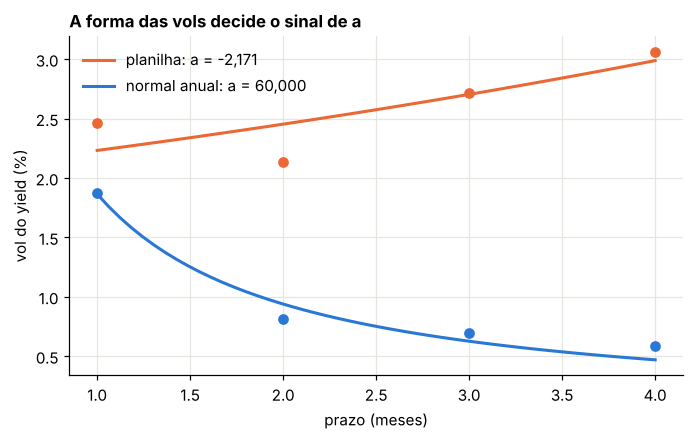

OK — com as vols da planilha, o ajuste pede reversão negativa (como a aba encontra)
OK — com as vols em unidades de taxa, a reversão é positiva


In [8]:
prazos = np.array([1, 2, 3, 4]) / 12
vols_planilha = np.array([0.02463782739818595, 0.021359591580382732, 0.02717743310261939, 0.03061581517918258])
vols_corretas = np.array([0.018739, 0.008153, 0.006940, 0.005888])    # Módulo 17, Laboratório 6


def sigma_R(T, a, s):
    return s * np.where(abs(a) < 1e-9, 1.0, (1 - np.exp(-a * T)) / (a * T))


def ajusta(vols):
    from scipy.optimize import least_squares
    res = least_squares(lambda p: sigma_R(prazos, *p) - vols, x0=[0.1, vols[0]], bounds=([-60, 1e-5], [60, 1.0]))
    return res.x


a_pl_fit, s_pl_fit = ajusta(vols_planilha)
a_ok_fit, s_ok_fit = ajusta(vols_corretas)
tab8 = pd.DataFrame({"estrutura de vols": ["planilha (×252, sem escala de prazo)", "normal anual (×√252)"],
                     "a ajustado": [a_pl_fit, a_ok_fit], "σ ajustado (%)": [100 * s_pl_fit, 100 * s_ok_fit],
                     "1/a (meses)": [12 / a_pl_fit, 12 / a_ok_fit]})
tabela(tab8)

fig, ax = plt.subplots()
Tf = np.linspace(1 / 12, 1 / 3, 50)
for v, (a_, s_), cor, nome in [(vols_planilha, (a_pl_fit, s_pl_fit), LARANJA, "planilha"), (vols_corretas, (a_ok_fit, s_ok_fit), AZUL, "normal anual")]:
    ax.plot(12 * prazos, 100 * v, "o", color=cor)
    ax.plot(12 * Tf, 100 * sigma_R(Tf, a_, s_), color=cor, label=f"{nome}: a = {f3(a_)}")
ax.set_xlabel("prazo (meses)"); ax.set_ylabel("vol do yield (%)"); ax.set_title("A forma das vols decide o sinal de a"); ax.legend()
plt.show()

ok(a_pl_fit < 0, "com as vols da planilha, o ajuste pede reversão negativa (como a aba encontra)")
ok(a_ok_fit > 0, "com as vols em unidades de taxa, a reversão é positiva")

Mesmo com as vols corretas, o ajuste vai para o limite superior permitido de $a$ ($1/a$ de poucos dias): a vol de 1 mês é mais que o dobro da de 2 meses, e um modelo de um fator com reversão constante só reproduz isso esquecendo os choques quase de imediato. Em 2023, a vol do T-bill de 1 mês carrega movimentos próprios desse prazo, que um fator não descreve.

**Cautela de Hull e White (1994).** Ajustar $a_i$ e $\sigma_i$ dependentes do tempo à vol de hoje faz a estrutura de vols **futura** ser muito diferente da atual: o modelo fica não estacionário, e o preço de opções que começam no futuro (opções sobre caps, swaptions *forward*) fica distorcido. A recomendação prática é manter $a$ e $\sigma$ constantes (ou $\sigma$ por trechos), calibrados a opções.

---
## 7. Black-Karasinski na mesma árvore

**Material: Black e Karasinski (1991); Itkin, Lipton e Muravey (2021); Silva (2010, UFRGS)**

### 7.1 O modelo

$$d\ln r = (\theta(t) - a\ln r)\,dt + \sigma\,dW.$$

A taxa é lognormal: sempre positiva, com volatilidade proporcional ao nível. Não há fórmula fechada para títulos nem para opções, e por isso a árvore é o método natural. A construção é a mesma: árvore de $x$ no estágio 1, e $\ln r_{m,j} = \alpha_m + j\Delta x$ no estágio 2. A diferença é que $\alpha_m$ não sai mais em forma fechada: resolvemos

$$\sum_jQ_{m,j}\exp\big(-e^{\alpha_m + j\Delta x}\Delta t\big) = P(0, (m + 1)\Delta t)$$

por Newton-Raphson, partindo do $\alpha_{m-1}$ (o método está na classe `ArvoreTaxaCurta`, com `modelo="BK"`).

Itkin, Lipton e Muravey (2021) lembram o outro lado: num ambiente de juros muito baixos ou negativos, o BK não consegue representar taxas negativas, e o pequeno deslocamento necessário muda a dinâmica; eles propõem uma modificação do tipo Verhulst. A dissertação de Silva (UFRGS, 2010) calibra uma versão generalizada do BK a títulos de desconto brasileiros.

### Laboratório 5 — HW e BK com o mesmo caplet no dinheiro

Calibramos o $\sigma$ do BK para que o caplet no dinheiro de 2 anos tenha o mesmo preço que no HW, e comparamos as vols de Black ao longo dos strikes e o piso das taxas.

,taxa-teto (%),vol Black HW (%),vol Black BK (%)
0,"3,475","21,765","18,287"
1,"4,225","19,827","18,287"
2,"4,975","18,300","18,300"
3,"5,725","17,057","18,304"
4,"6,475","16,020","18,284"


σ do BK (lognormal): 20,242 % | erro de ajuste da curva no BK: 1.1e-16
menor taxa nos nós da data 2 anos — HW: -17,294 % | BK: 0,053 %


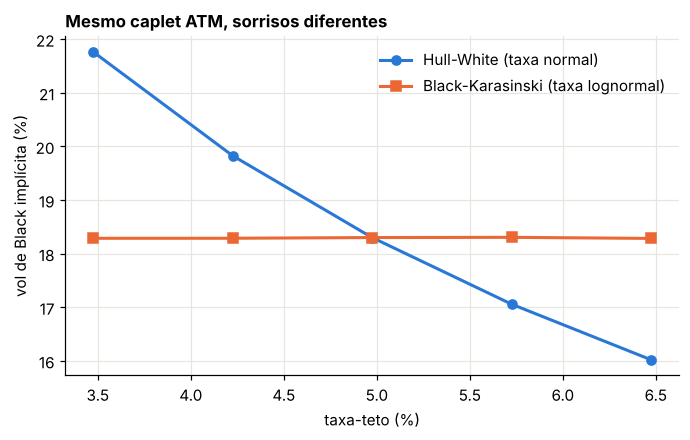

OK — o BK, com Newton em cada data, também reprecifica a curva exatamente
OK — o BK produz vols de Black quase planas; o HW, um skew
OK — o BK não tem taxas negativas; o HW tem


In [9]:
def caplets_modelo(arv):
    PB = arv.zero_cupom(nk, N7)
    return np.array([caplet_arvore(arv, PB, k) for k in taxas_teto])


def vol_black(preco, k):
    return brentq(lambda v: caplet_black(k, v) - preco, 1e-4, 3.0)


atm_hw = c_arv[2]
s_bk = brentq(lambda s: caplets_modelo(ArvoreTaxaCurta(A_HW, s, dt7, N7, P_merc, "BK"))[2] - atm_hw, 0.05, 0.6)
arv_bk = ArvoreTaxaCurta(A_HW, s_bk, dt7, N7, P_merc, "BK")
c_bk = caplets_modelo(arv_bk)
tab9 = pd.DataFrame({"taxa-teto (%)": 100 * taxas_teto,
                     "vol Black HW (%)": [100 * vol_black(c, k) for c, k in zip(c_arv, taxas_teto)],
                     "vol Black BK (%)": [100 * vol_black(c, k) for c, k in zip(c_bk, taxas_teto)]})
tabela(tab9)
print("σ do BK (lognormal):", f3(100 * s_bk), "% | erro de ajuste da curva no BK:", f"{abs(arv_bk.Q[N7].sum() - P_merc(N7 * dt7)):.1e}")
print("menor taxa nos nós da data 2 anos — HW:", f3(100 * arv7.taxa(nk).min()), "% | BK:", f3(100 * arv_bk.taxa(nk).min()), "%")

fig, ax = plt.subplots()
ax.plot(tab9["taxa-teto (%)"], tab9["vol Black HW (%)"], "o-", color=AZUL, label="Hull-White (taxa normal)")
ax.plot(tab9["taxa-teto (%)"], tab9["vol Black BK (%)"], "s-", color=LARANJA, label="Black-Karasinski (taxa lognormal)")
ax.set_xlabel("taxa-teto (%)"); ax.set_ylabel("vol de Black implícita (%)"); ax.set_title("Mesmo caplet ATM, sorrisos diferentes")
ax.legend(); plt.show()

ok(abs(arv_bk.Q[N7].sum() - P_merc(N7 * dt7)) < 1e-14, "o BK, com Newton em cada data, também reprecifica a curva exatamente")
ok(np.ptp(tab9["vol Black BK (%)"]) < 0.2 * np.ptp(tab9["vol Black HW (%)"]), "o BK produz vols de Black quase planas; o HW, um skew")
ok(arv_bk.taxa(nk).min() > 0 > arv7.taxa(nk).min(), "o BK não tem taxas negativas; o HW tem")

**O que aprendemos.** A escolha entre HW e BK é uma escolha sobre o sorriso de vol. O HW, normal, dá vols de Black decrescentes no strike e admite juros negativos; o BK, lognormal, dá vols de Black quase planas e juros sempre positivos. Qual ajusta melhor depende do mercado e da época: com juros altos, o skew observado costuma ficar entre os dois.

---
## 8. Síntese

| Etapa | O que fazer | Laboratório |
|---|---|---|
| Geometria | $\Delta x = \sigma\sqrt{3\Delta t}$, probabilidades por momentos, troca em $j_{max} = \lceil 0{,}184/(a\Delta t)\rceil$ | 1 |
| Ajuste à curva | indução para a frente com Arrow-Debreu: $\theta_i$ aproximado (C&S) ou $\alpha_m$ exato (HW 1994) | 2 e 3 |
| Conferência | soma dos $Q$ confere preços, não posições; conferir momentos nó a nó e reprecificar opções | 2 |
| Avaliação | indução para trás; exercício antecipado por comparação nó a nó | 5.1 a 5.3 |
| Volatilidades | ajustar vols com $a_i$ variável é instável; a forma das vols decide o sinal de $a$ | 4 |
| Outro modelo | BK na mesma árvore, $\alpha_m$ por Newton | 5 |

## 9. Notas sobre a planilha HW_arvore_final

| Onde | Observação |
|---|---|
| "HW yield", células D75, D80 e D86 | os três ramos do nó $(1, -1)$ são somados um nível acima; a soma dos $Q$ não muda (a conferência "sum(Q)" passa), mas $\theta_2$ sai $-4{,}88\%$ em vez de $-0{,}20\%$ ao ano |
| "HW yield" | ramificação normal em todos os nós; adequado para poucos passos, mas para árvores longas é preciso a troca de ramificação da Seção 2.3 |
| "HW yield and vol" | as vols de entrada crescem com o prazo por causa da anualização (Módulo 17), o que leva a reversão negativa ($a_1 = -6{,}31$; $a_2 = -1{,}60$) |
| Ambas | $a$ igual à taxa de 1 mês (Módulo 17) |

## 10. Exercícios

**Exercício 1.** Mostre que, com $j = 0$ e $\Delta x = \sigma\sqrt{3\Delta t}$, as probabilidades são $(1/6, 2/3, 1/6)$, e que a curtose da distribuição de um passo é 3, como a da normal.

<details><summary>Solução</summary>

Com $\eta = 0$: $p_u = p_d = \sigma^2\Delta t/(2\Delta x^2) = 1/6$, $p_m = 2/3$. O quarto momento é $2 \cdot \frac16\Delta x^4 = \frac13\Delta x^4 = 3\sigma^4\Delta t^2$, e o quadrado da variância é $\sigma^4\Delta t^2$: curtose 3. É por isso que $\sqrt3$ é a escolha natural.
</details>

**Exercício 2.** Construa a árvore de dois estágios com os dados da planilha (yields de 1 a 4 meses, $\Delta t = 1/12$). Compare os $\alpha_m$ com os $r_{0,0}$ e $\theta_i$ da Seção 3.

<details><summary>Solução</summary>

Use `ArvoreTaxaCurta(a, s, 1/12, 4, P)`, com `P` interpolando $e^{-R(i)\,i\Delta t}$ nas datas da grade. O $\alpha_0$ é exatamente $R(1)$. Os demais diferem dos de C&S porque lá a árvore é centrada em $r_{0,0}$ e o drift vai para as probabilidades; aqui o drift vai para o deslocamento $\alpha_m$.
</details>

**Exercício 3.** Calcule o delta do título com opção de recompra em relação a um deslocamento paralelo da curva (reconstrua a árvore com $P(0, t)e^{-\epsilon t}$) e compare com o do título simples. Por que o *callable* tem duração menor?

<details><summary>Solução</summary>

Quando os juros caem, o título simples sobe sem limite, mas o *callable* fica preso perto do par, porque o emissor resgata. A sensibilidade a juros (duração efetiva) do *callable* é menor, e pode ficar muito pequena quando o título está perto do preço de recompra: é a convexidade negativa.
</details>

**Exercício 4.** No Laboratório 5, encontre um $\sigma$ do HW e um do BK que reproduzam ao mesmo tempo os caplets de 2 anos com taxa-teto 1,5 ponto abaixo e 1,5 ponto acima do dinheiro. É possível? O que isso sugere?

<details><summary>Solução</summary>

Com um único parâmetro de vol, cada modelo tem uma inclinação de sorriso fixa: não dá para acertar dois strikes com inclinação diferente da do modelo. Isso motiva modelos com parâmetro de forma, como o CEV na taxa curta ($dr = \dots + \sigma r^\beta dW$, §9.4 de Clewlow e Strickland), em que $\beta$ interpola entre o normal ($\beta = 0$) e o lognormal ($\beta = 1$).
</details>

In [10]:
print(f"Módulo 18 concluído: {_checks['n']} verificações aprovadas.")

Módulo 18 concluído: 25 verificações aprovadas.
